# Template


### Modules importation

In [84]:
import timm
import torch
import random
import pandas as pd
import numpy as np
import torch.nn as nn
import copy, time
import matplotlib.pyplot as plt
from PIL import Image
from timm.data.config import resolve_data_config # allow to correct inputs data by mean/std from the imported model
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from torchinfo import summary
from torchview import draw_graph
from sklearn.metrics import f1_score, classification_report, confusion_matrix, accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns

device="cuda" if torch.cuda.is_available() else "cpu" # if you have a GPU it runs on GPU

from pathlib import Path


In [85]:
device

'cuda'

### Architecture

In [86]:
class ImageDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx])

        if self.transform:
            image = self.transform(image)

        return image, self.labels[idx]

In [87]:
class ZoobotConvNeXt(nn.Module):
    """Pretrained Encoder. Could be ConveNext or ResNEt"""

    # 1. set up functions
    def __init__(
        self,
        num_classes: int = 3,
        model_name: str = "hf_hub:mwalmsley/zoobot-encoder-resnet101",  # this one lead to the best results on the zoobot benchmark
        pretrained: bool = True,
        checkpoint_path: str | None = None,
        freeze_backbone: bool = True,
        device: str | None = None,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")  # if you have a GPU it runs on GPU

        # Pas besoin de télécharger les poids pré-entraînés si on charge un checkpoint local
        use_pretrained = False if checkpoint_path is not None else pretrained

        self.model = timm.create_model(
            model_name, pretrained=use_pretrained, num_classes=num_classes
        )
        # get the mean and std (parameters from pretrained model)
        self.data_config = resolve_data_config({}, model=self.model)

        self.to(self.device)

        if checkpoint_path is not None:
            self.load(checkpoint_path)

        if freeze_backbone:
            self.freeze_backbone()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

    def freeze_backbone(self):
    
        head_ids = {id(p) for p in self.model.get_classifier().parameters()}
        for p in self.model.parameters():
            p.requires_grad = id(p) in head_ids

    def unfreeze_backbone(self):
        for param in self.model.parameters():
            param.requires_grad = True

    # 2. Data related functions
    def get_transforms(self, train: bool = True, size: int = 224):  # Allow data augmentation
        mean, std = self.data_config["mean"], self.data_config["std"]
        if train:
            return transforms.Compose([
                transforms.Resize((size, size)),
                transforms.RandomHorizontalFlip(),
                transforms.RandomVerticalFlip(),
                transforms.RandomRotation(180),
                transforms.ToTensor(),
                transforms.Normalize(mean, std),
            ])
        return transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])

    def get_dataloaders(self, images, labels, train_idx, val_idx, batch_size=32, num_workers=0):
        train_dataset = ImageDataset(
            images[train_idx],
            labels[train_idx],
            transform=self.get_transforms(train=False) # right now augmentation is disabled, put train=True to enable it
        )
        val_dataset = ImageDataset(
            images[val_idx],
            labels[val_idx],
            transform=self.get_transforms(train=False)
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=num_workers
        )
        val_loader = DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers
        )

        return train_loader, val_loader

    # 3. Training functions
    def fit(self, train_loader, val_loader=None, epochs=10, lr=1e-3, weight_decay=1e-2):
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(
            (p for p in self.parameters() if p.requires_grad),
            lr=lr,
            weight_decay=weight_decay,
        )
        history = {"train_loss": [], "val_loss": [], "val_acc": []}

        for epoch in range(epochs):
            self.train()
            running_loss = 0.0
            for images, labels in train_loader:
                images, labels = images.to(self.device), labels.to(self.device)

                optimizer.zero_grad()
                loss = criterion(self(images), labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item()

            train_loss = running_loss / len(train_loader)
            history["train_loss"].append(train_loss)
            msg = f"Epoch {epoch + 1}/{epochs} - train loss: {train_loss:.4f}"

            if val_loader is not None:
                val_loss, val_acc = self.evaluate(val_loader)
                history["val_loss"].append(val_loss)
                history["val_acc"].append(val_acc)
                msg += f" - val loss: {val_loss:.4f} - val acc: {val_acc:.4f}"
            print(msg)

        return history

    @torch.no_grad()
    def evaluate(self, loader):
        self.eval()
        criterion = nn.CrossEntropyLoss(reduction="sum")
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(self.device), labels.to(self.device)
            outputs = self(images)
            total_loss += criterion(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        return total_loss / total, correct / total

    # 4. Inference function
    @torch.no_grad()
    def predict(self, images: torch.Tensor) -> torch.Tensor:
        """Retourne les probabilités par classe pour un batch d'images."""
        self.eval()
        return torch.softmax(self(images.to(self.device)), dim=1)

    # 5. Load and save functions
    def save(self, path = "zoobot_convnext.pth"):
        torch.save(self.state_dict(), path)

    def load(self, path = "zoobot_convnext.pth"):
        state_dict = torch.load(path, map_location=self.device, weights_only=True)
        self.load_state_dict(state_dict)

### Model set up

In [88]:
# Parameters 
n_classes = 10
freeze_backbone = True
choosen_model = "https://huggingface.co/collections/mwalmsley/zoobot-encoders?sort=downloads"
pretrained = True

In [98]:
# Definition of the classifier
classifier =  ZoobotConvNeXt(num_classes=n_classes, freeze_backbone=freeze_backbone,pretrained=pretrained,checkpoint_path=None)

### Data importation

#### Constants

In [99]:
VALIDATION_SIZE = 0.2
DATA_DIR = "data"
LABELS_FILE = "data/train.csv"
IMAGE_SIZE = 256
BATCH_SIZE = 32

#### Training/validation split

In [100]:
def make_split(data_dir, labels_file, batch_size, val_size=0.2):
    """Stratified training and validation loaders."""

    df = pd.read_csv(labels_file)

    # Load images
    X = np.stack([
        np.array(
            Image.open(f"{data_dir}/train/{img_id}.png")
        )
        for img_id in df["id"]
    ])

    labels = df["label"].values

    # Encode labels
    classes = sorted(np.unique(labels))
    class_to_idx = {label: i for i, label in enumerate(classes)}
    labels = np.array([class_to_idx[label] for label in labels], dtype=np.int64)

    # Stratified split
    train_idx, val_idx = train_test_split(
        np.arange(len(labels)),
        test_size=val_size,
        stratify=labels
    )
    return X, labels, train_idx, val_idx

X, labels, train_idx, val_idx = make_split(DATA_DIR, LABELS_FILE, batch_size=BATCH_SIZE, val_size=VALIDATION_SIZE)
train_loader, val_loader = classifier.get_dataloaders(X, labels, train_idx, val_idx, BATCH_SIZE)
xb, yb = next(iter(train_loader))
input_shape = tuple(xb.shape[1:])
print(f"Features batch shape: {xb.shape}")
print(f"Labels batch shape: {yb.shape}")

Features batch shape: torch.Size([32, 3, 224, 224])
Labels batch shape: torch.Size([32])


#### A little bit of visualization

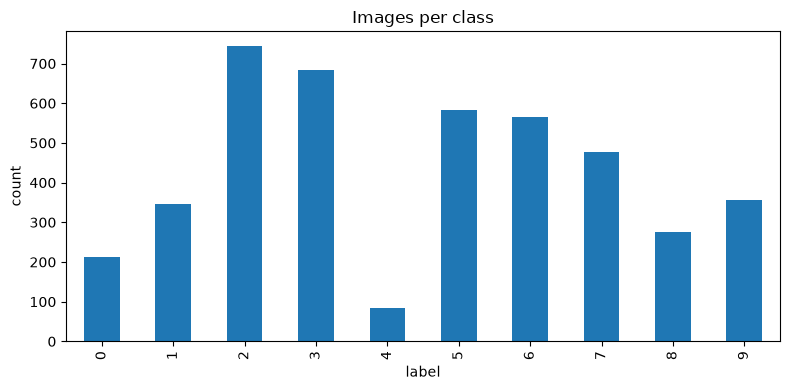

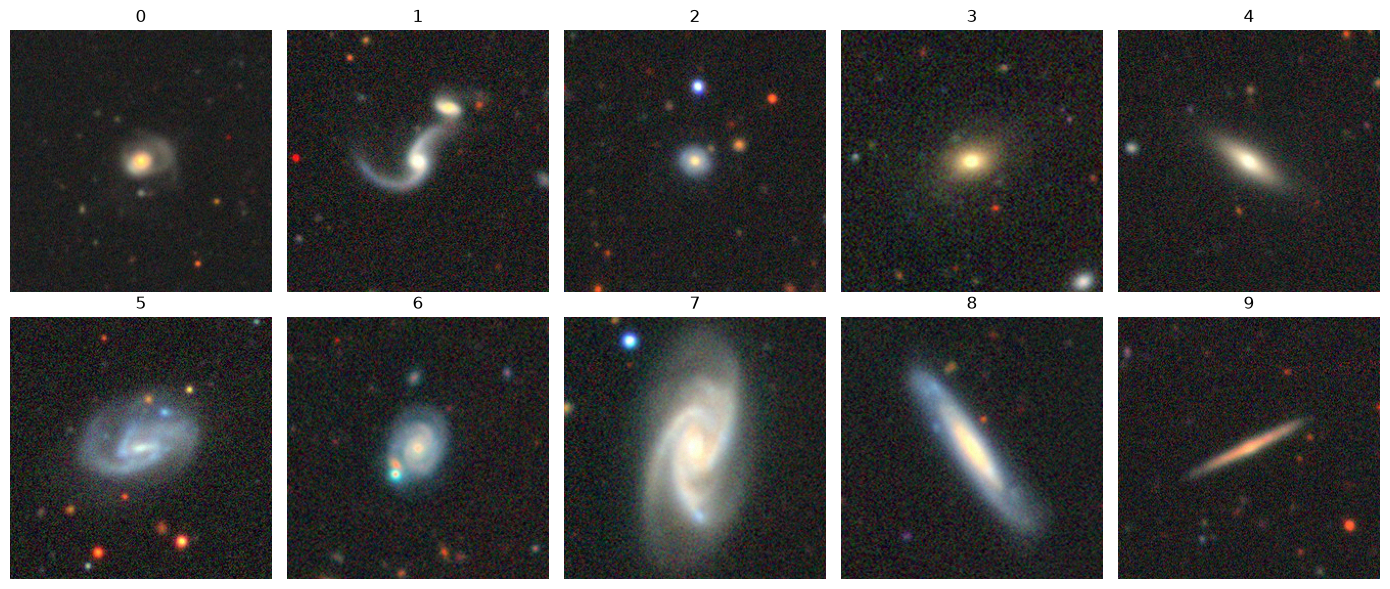

In [92]:
df = pd.read_csv(LABELS_FILE)
classes = sorted(df["label"].unique())

# Class distribution
counts = df["label"].value_counts().reindex(classes)
plt.figure(figsize=(8, 4))
counts.plot(kind="bar")
plt.title("Images per class")
plt.ylabel("count")
plt.tight_layout()
plt.show()

# One example per class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, c in zip(axes.ravel(), classes):
    img_id = df[df["label"] == c]["id"].iloc[0]
    ax.imshow(Image.open(f"{DATA_DIR}/train/{img_id}.png"))
    ax.set_title(str(c))
    ax.axis("off")
plt.tight_layout()
plt.show()

### Training

In [101]:
#Summary of the model 
print(summary(classifier))

Layer (type:depth-idx)                        Param #
ZoobotConvNeXt                                --
├─ResNet: 1-1                                 --
│    └─Conv2d: 2-1                            (9,408)
│    └─BatchNorm2d: 2-2                       (128)
│    └─ReLU: 2-3                              --
│    └─MaxPool2d: 2-4                         --
│    └─Sequential: 2-5                        --
│    │    └─Bottleneck: 3-1                   (75,008)
│    │    └─Bottleneck: 3-2                   (70,400)
│    │    └─Bottleneck: 3-3                   (70,400)
│    └─Sequential: 2-6                        --
│    │    └─Bottleneck: 3-4                   (379,392)
│    │    └─Bottleneck: 3-5                   (280,064)
│    │    └─Bottleneck: 3-6                   (280,064)
│    │    └─Bottleneck: 3-7                   (280,064)
│    └─Sequential: 2-7                        --
│    │    └─Bottleneck: 3-8                   (1,512,448)
│    │    └─Bottleneck: 3-9                   (1,1

In [ ]:
draw_graph(classifier, input_size=(1, *input_shape),
           depth=3).visual_graph

In [102]:
# @title Training and evaluation helpers
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']

def score(y_true, y_pred, metric):
    """Monitored metric: 'accuracy', or 'f1' for the F1 score averaged over the classes (macro)."""
    if metric == 'accuracy':
        return accuracy_score(y_true, y_pred)
    return f1_score(y_true, y_pred, average='macro', zero_division=0)


def plot_history(history, max_epochs=None):
    """Plot training and validation curves of the loss and of the metric, marking the best epoch."""
    titles = {'loss': 'Loss', 'accuracy': 'Accuracy', 'f1': 'F1 score (macro)'}
    metrics = [key.removeprefix('train_') for key in history if key.startswith('train_')]
    fig, axes = plt.subplots(1, len(metrics), figsize=(16, 4.5))
    epochs = range(1, len(history['train_loss']) + 1)

    for ax, metric in zip(axes, metrics):
        ax.plot(epochs, history[f'train_{metric}'], color=PALETTE[0], label='Training')
        ax.plot(epochs, history[f'val_{metric}'], color=PALETTE[1], label='Validation')
        if 'best_epoch' in history:
            ax.axvline(history['best_epoch'], color='#898781', linestyle='--', linewidth=1, label='Best epoch')
        ax.set(title=titles.get(metric, metric), xlabel='Epoch', xlim=(1, max_epochs or len(epochs)))
        ax.legend()

    plt.tight_layout()
    plt.show()


def predict(model, loader, device):
    """Return true and predicted labels for every sample in a loader."""
    model.eval()
    targets, preds = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x.to(device)).argmax(dim=1).cpu())
            targets.append(y)
    return torch.cat(targets).numpy(), torch.cat(preds).numpy()


def print_metrics(y_true, y_pred):
    """Print accuracy, the macro precision, recall and F1 score, and the weighted F1 score."""
    print(f"Accuracy:            {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision (macro):   {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"Recall (macro):      {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 score (macro):    {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 score (weighted): {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")


def train_one_epoch(model, loader, criterion, optimizer, scaler, device, metric):
    """Run one training epoch with mixed precision; return mean loss and the metric."""
    model.train()
    total_loss, targets, preds = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        # Forward pass in mixed precision (on the GPU only)
        with torch.autocast(device_type=torch.device(device).type, enabled=torch.device(device).type == 'cuda'):
            logits = model(x)
            loss = criterion(logits, y)

        # Backward pass on the scaled loss; the scaler unscales the gradients before the update
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * x.size(0)
        targets.append(y.cpu())
        preds.append(logits.argmax(dim=1).cpu())
    return total_loss / len(loader.dataset), score(torch.cat(targets), torch.cat(preds), metric)


def evaluate(model, loader, criterion, device, metric):
    """Return mean loss and the metric on a loader, without updating the weights."""
    model.eval()
    total_loss, targets, preds = 0.0, [], []
    with torch.no_grad(), torch.autocast(device_type=torch.device(device).type, enabled=torch.device(device).type == 'cuda'):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += criterion(logits, y).item() * x.size(0)
            targets.append(y.cpu())
            preds.append(logits.argmax(dim=1).cpu())
    return total_loss / len(loader.dataset), score(torch.cat(targets), torch.cat(preds), metric)


def fit(model, train_loader, val_loader, criterion, optimizer, device, epochs, metric='accuracy',
        patience=0, verbose=10, live=0, callback=None):
    """Train for up to `epochs` epochs with mixed precision and return the history.

    With patience > 0, stop after `patience` epochs without improvement of the validation
    metric and restore the weights of the best epoch. A log line every `verbose` epochs and live
    plots every `live` epochs (0 switches them off); `callback(model, epoch)` after every epoch.
    """
    history = {'train_loss': [], 'val_loss': [], f'train_{metric}': [], f'val_{metric}': []}
    best_score, best_state, wait = -np.inf, None, 0
    log, start = [], time.time()

    # Gradient scaler for mixed precision, active only on the GPU
    scaler = torch.amp.GradScaler(enabled=torch.device(device).type == 'cuda')

    for epoch in range(1, epochs + 1):
        train_loss, train_score = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, metric)
        val_loss, val_score = evaluate(model, val_loader, criterion, device, metric)
        for key, value in zip(history, [train_loss, val_loss, train_score, val_score]):
            history[key].append(value)
        if callback is not None:
            callback(model, epoch)

        # Keep a copy of the best weights seen so far
        if val_score > best_score:
            best_score, wait = val_score, 0
            history['best_epoch'] = epoch
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        stop = patience > 0 and wait >= patience

        # A log line and the live plots are due on the first and the last epoch, and every `verbose` and `live` epochs
        due = lambda every: every > 0 and (epoch == 1 or epoch % every == 0 or epoch == epochs or stop)
        if due(verbose):
            log.append(f"Epoch {epoch:3d}/{epochs} | Train: loss {train_loss:.4f}, {metric} {train_score:.4f} | "
                       f"Val: loss {val_loss:.4f}, {metric} {val_score:.4f}")
            if not live:
                print(log[-1])
        if due(live):
            clear_output(wait=True)
            plot_history(history, max_epochs=epochs)
            print('\n'.join(log))
        if stop:
            if verbose:
                print(f"Early stopping at epoch {epoch}")
            break

    # With early stopping, go back to the weights of the best epoch
    if patience > 0:
        model.load_state_dict(best_state)
    history['seconds'] = time.time() - start
    if verbose:
        kept = 'weights restored' if patience > 0 else 'weights of the last epoch kept'
        print(f"Best epoch {history['best_epoch']} | val {metric} {best_score:.4f} ({kept})")
    return history


def predict_proba(model, loader, device):
    """Return true labels and predicted class probabilities for every sample in a loader."""
    model.eval()
    targets, probs = [], []
    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
        for x, y in loader:
            probs.append(torch.softmax(model(x.to(device)).float(), dim=1).cpu())
            targets.append(y)
    return torch.cat(targets).numpy(), torch.cat(probs).numpy()


def record_gradients(model, record, epoch, layers=None, every=5, max_values=10_000):
    """Append a sample of the gradients of each layer to `record`, on the first epoch and then every `every` epochs.

    By default the layers are the linear and recurrent modules; `layers` (a dict name -> module) can group them.
    """
    if epoch > 1 and epoch % every:
        return
    if layers is None:
        modules = [module for module in model.modules() if isinstance(module, (nn.Linear, nn.RNNBase))]
        layers = {f'Layer {i} ({type(module).__name__})': module for i, module in enumerate(modules, start=1)}
    record['epochs'].append(epoch)
    for name, layer in layers.items():
        grads = [param.grad.flatten() for param in layer.parameters() if param.grad is not None]
        if grads:
            values = torch.cat(grads)
            values = values[torch.isfinite(values)]
            record['gradients'].setdefault(name, []).append(values[::max(1, values.numel() // max_values)].cpu().numpy())


def plot_histograms(tensors, epochs, columns=5):
    """TensorBoard-style histograms of the gradients of each layer over the recorded epochs, the oldest at the back.

    Exact zeros are left out and the axis covers the central 98% of the values. At most `columns` panels per row.
    """
    colours = sns.blend_palette(['#fbd6c4', '#7a2a0a'], as_cmap=True)
    kernel = np.exp(-0.5 * np.linspace(-2, 2, 9) ** 2)
    cols = min(columns, len(tensors))
    rows = -(-len(tensors) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 5 * rows), squeeze=False)
    for ax in axes.flat[len(tensors):]:
        ax.axis('off')

    for ax, (name, slices) in zip(axes.flat, tensors.items()):
        slices = [values[values != 0] for values in slices]
        n = len(slices)

        # Bins over the central 98%, widened by 15% on each side so that the smoothed tails are not clipped
        low, high = np.percentile(np.concatenate(slices), [1, 99])
        margin = 0.15 * (high - low) + 1e-8
        bins = np.linspace(low - margin, high + margin, 81)
        centres = (bins[:-1] + bins[1:]) / 2

        # Histogram of each slice, smoothed with a small Gaussian
        counts = np.stack([np.convolve(np.histogram(values, bins)[0], kernel, mode='same') for values in slices])
        heights = 5 * counts / max(counts.max(), 1)

        # One ridge per slice, from the oldest (top, back) to the newest (bottom, front)
        for k, height in enumerate(heights):
            ax.fill_between(centres, n - 1 - k, n - 1 - k + height, facecolor=colours(k / max(1, n - 1)),
                            edgecolor='white', linewidth=0.6, zorder=k)

        ticks = range(0, n, max(1, round(n / 5)))
        ax.set_yticks([n - 1 - k for k in ticks], [epochs[k] for k in ticks])
        ax.yaxis.tick_right()
        ax.yaxis.set_label_position('right')
        ax.set(title=name, xlabel='Gradient', ylabel='Epoch', xlim=(bins[0], bins[-1]))
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.ticklabel_format(axis='x', style='sci', scilimits=(-2, 3))
        ax.grid(False)

    plt.tight_layout()
    plt.show()

In [ ]:
#Hyperparameters
LEARNING_RATE = 1e-3
FINE_TUNING_LEARNING_RATE = 1e-5
EPOCHS = 200
DROPOUT_RATE = 0.1
WEIGHT_DECAY= 1e-2

# Stages of the backbone that train during fine-tuning
FINE_TUNED_STAGES = 0

# Metric monitored on the validation set: the breeds are balanced, so the accuracy
METRIC = 'f1'

# Epochs without improvement of the validation metric before early stopping
PATIENCE = 10

criterion = nn.CrossEntropyLoss()

def count_trainable(model):
    """Number of parameters that receive gradients."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def stage_layers(model):
    """The 9 stages of the backbone and the classifier: one gradient histogram each."""
    layers = {f'Stage {i}': stage for i, stage in enumerate(model.backbone.features)}
    layers['Classifier'] = model.backbone.classifier
    return layers

In [18]:
# Trained models and their histories, one entry per experiment
models, histories = {}, {}

In [97]:
%%time
#entrainement avec les fonctions de la classe, on peut aussi faire avec les fonctions des TP (plus complètes)
model = classifier.to(device)
print(f"Trainable parameters: {count_trainable(model):,}")
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY) 
record = {'epochs': [], 'gradients': {}}
#history = model.fit(train_loader, val_loader, epochs=1, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
fit(model, train_loader, val_loader, criterion, optimizer, device, EPOCHS, metric=METRIC,patience=10)
history = fit()
models['test0'], histories['test0'] = model, history
model.save(path="saved_models/chosen_model.pth")

Trainable parameters: 20,490
CPU times: total: 1min 35s
Wall time: 12.3 s


KeyboardInterrupt: 

In [ ]:
# The gradients of each stage (si on utilise les fonctions hors classes)
plot_histograms(record['gradients'], record['epochs'])

### Performance metrics

In [ ]:
# Check whether the required objects are available.
required = [
    "model", "val_loader", "device", "n_classes", "predict"
]

for name in required:
    print(name, "OK" if name in globals() else "MISSING")

In [ ]:
# Collect true and predicted classes for the entire validation set.
# Reuse the predict() function from the TD helpers.
# No weights are updated during this evaluation.
y_true, y_pred = predict(model, val_loader, device)

# Compute the competition metric.
# Weighted F1 gives each class a weight proportional to its true frequency.
# Compute it over the full validation set, not separately for each batch.
weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Validation weighted F1: {weighted_f1:.4f}")

# Inspect each class: a good overall score can hide poor results
# on classes with fewer examples.
# Support is the number of true examples belonging to each class.
class_indices = list(range(n_classes))

# Class names in the official label order (0 to 9).
class_names = [
    "Spaghetti alla rinfusa",
    "Gemelli",
    "Gnocchi",
    "Ravioli",
    "Penne",
    "Fusilli con la sbarra",
    "Fusilli stretti",
    "Riccioli",
    "Linguine",
    "Lasagna"
]


print("\nPerformance by class:")
print(classification_report(
    y_true,
    y_pred,
    labels=class_indices,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Visualise which classes are confused.
# Rows are true classes; columns are predicted classes.
# Diagonal entries are correct predictions. Values are image counts.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_indices
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Validation — Confusion matrix")
plt.tight_layout()
plt.show()

### Kaggle submission

In [ ]:

# Use the dataset structure agreed by the team.
test_dir = Path(DATA_DIR) / "test"
sample_path = Path(DATA_DIR) / "sample_submission.csv"
output_path = Path("submission.csv")

# Preserve the image order required by Kaggle.
submission = pd.read_csv(sample_path)

# Recover the class encoding used during training.
original_labels = sorted(
    pd.read_csv(LABELS_FILE)["label"].unique()
)

# Apply the same deterministic preprocessing as validation.
test_transform = model.get_transforms(train=False)
model_device = next(model.parameters()).device

image_paths = [
    test_dir / f"{image_id}.png"
    for image_id in submission["id"]
]

# Check inputs before running inference.
assert submission["id"].is_unique, "Duplicate image IDs."
assert len(original_labels) == n_classes, "Unexpected class count."

missing = [path for path in image_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing image: {missing[0]}")

test_labels = []
model.eval()

# Predict without computing gradients or updating weights.
with torch.no_grad():
    for start in range(0, len(image_paths), BATCH_SIZE):
        images = []

        for path in image_paths[start:start + BATCH_SIZE]:
            with Image.open(path) as image:
                tensor = test_transform(image.convert("RGB"))
            images.append(tensor)

        # Compute one score per class and select the highest.
        batch = torch.stack(images).to(model_device)
        logits = model(batch)
        indices = logits.argmax(dim=1).cpu().tolist()

        # Convert internal indices back to competition labels.
        test_labels.extend(original_labels[i] for i in indices)

# Save exactly one prediction per image, without an extra index column.
assert len(test_labels) == len(submission)
submission["label"] = test_labels
assert submission["label"].isin(range(10)).all()

submission[["id", "label"]].to_csv(output_path, index=False)

print(f"Saved {len(submission)} predictions to {output_path.resolve()}")
print(submission.head())